# 26 · Online learning and drift: models age, and you have to notice

Every model is trained on the past and used on the future. When the future stops looking like the past, quality decays, usually quietly: no error is raised, the answers are just a little worse every week. This notebook measures that decay and the two standard responses, **updating the model** and **detecting drift**:

| question | measured here |
|---|---|
| how fast does a frozen model age? | next-item recommendation on MovieLens-1M, week by week after training |
| what do updates buy? | the same models retrained weekly, on a sliding window, and updated online after every event |
| can we detect the change without labels? | PSI on the item distribution, the share of never-seen items, and drift-triggered retraining |
| does this apply to LLM applications? | detecting a shift in what users ask, from embeddings alone, with three detectors |

Read it **after notebook 12**: it reuses MovieLens-1M and its loader, and turns notebook 12's single offline evaluation into a stream over time.

**Sources.** Huyen, *Designing Machine Learning Systems*, ch. 8–9 (distribution shifts, continual learning), and *AI Engineering*, ch. 10 (monitoring); Gama et al. (2014), *A Survey on Concept Drift Adaptation*.

## Background: what drifts, and what to do about it

### Kinds of drift

Write the data as inputs $x$ and outcomes $y$:

- **Covariate shift**: $P(x)$ changes, $P(y \mid x)$ does not. New users from a new country, a new kind of question to a chatbot.
- **Label (prior) shift**: $P(y)$ changes. A new blockbuster takes a large share of all views.
- **Concept drift**: $P(y \mid x)$ changes. The same user history now leads to different choices, because tastes or the catalogue moved.

Drift can be **sudden** (a launch, a policy change), **gradual** or **recurring** (weekends, seasons). Some is caused by the model itself: a recommender shapes what users see and so what they click next (a *feedback loop*, notebook 12's exploration section).

### Responses: update the model

- **Periodic retraining** on all data so far, or on a **sliding window** that forgets the old.
- **Online (incremental) learning**: update after every event or mini-batch, as with SGD, or as with counts that decay exponentially so recent events weigh more. It is fresh, but it needs care: bad data goes live immediately, and models can forget (catastrophic forgetting, for neural nets).
- **Warm starting**: continue training from the last model on new data, which is cheaper than starting over.

### Responses: detect the change

Labels often arrive late or never, so drift is monitored on **inputs and outputs**:
- **PSI (population stability index)**: $\mathrm{PSI} = \sum_b (p_b - q_b) \ln(p_b / q_b)$ over bins $b$ of a reference distribution $q$ and a current one $p$. Common rule of thumb: < 0.1 stable, 0.1–0.25 moderate, > 0.25 major shift.
- **KS and chi-squared tests** per feature, and the **KL / Jensen-Shannon divergence**.
- **For embeddings** (text, images): compare the two clouds of vectors with the distance between their centroids, the **maximum mean discrepancy** (MMD; Gretton et al., 2012) with a permutation test, or a **classifier two-sample test**: if a classifier can tell reference from current data apart (AUC well above 0.5), they differ (Lopez-Paz & Oquab, 2017).

### Evaluating models on a stream: prequential

On streams, the honest evaluation is **prequential** ("test-then-train"): each event is first predicted with the model as it is, then used for learning. Every prediction is out of sample, and the score over time shows how the model ages.

### Key references

- Gama, Žliobaitė, Bifet, Pechenizkiy & Bouchachia (2014), *A Survey on Concept Drift Adaptation*.
- Lu et al. (2018), *Learning under Concept Drift: A Review*.
- Gretton et al. (2012), *A Kernel Two-Sample Test* (MMD).
- Lopez-Paz & Oquab (2017), *Revisiting Classifier Two-Sample Tests*.
- Rabanser, Günnemann & Lipton (2019), *Failing Loudly: An Empirical Study of Methods for Detecting Dataset Shift*.
- Harper & Konstan (2015), *The MovieLens Datasets: History and Context*.

In [1]:
import os, sys, json, time, random, warnings
ROOT = os.path.abspath(".")
while not os.path.isdir(os.path.join(ROOT, "llm_edu_suite")) and os.path.dirname(ROOT) != ROOT:
    ROOT = os.path.dirname(ROOT)                    # walk up from notebooks/<topic>/ to the repo root
sys.path.insert(0, ROOT)
import numpy as np
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore", category=DeprecationWarning)
random.seed(0); np.random.seed(0)

from llm_edu_suite.config import setup, get_llm, get_embeddings
info = setup(project="llm-edu-suite-26-drift")           # loads .env, picks the LangSmith project, checks that Ollama is up

provider        : ollama
chat_model      : qwen2.5:3b
judge_model     : qwen2.5:7b
embedding_model : nomic-embed-text
ollama_running  : True
langsmith       : off (add LANGSMITH_API_KEY to .env to enable)


In [2]:
warnings.filterwarnings("ignore")
import datetime as dt
from collections import defaultdict
from llm_edu_suite.recsys import download_movielens_1m, load_movielens_1m

ml = load_movielens_1m(download_movielens_1m())
events = sorted((t, u, i) for u, es in ml.events.items() for t, i, _ in es)          # one global stream, in time order
T = np.array([e[0] for e in events]); U_ = np.array([e[1] for e in events]); I_ = np.array([e[2] for e in events])
N_ITEMS = ml.n_items + 1
day = lambda s: dt.datetime.fromtimestamp(int(s), dt.timezone.utc).date()
CUT = dt.datetime(2000, 8, 1, tzinfo=dt.timezone.utc).timestamp()
END = dt.datetime(2001, 1, 1, tzinfo=dt.timezone.utc).timestamp()
WEEK = 7 * 24 * 3600
windows = [(s, min(s + WEEK, END)) for s in np.arange(CUT, END, WEEK)]
train_mask = T < CUT
print(f"{len(events):,} ratings from {day(T[0])} to {day(T[-1])} | training: {train_mask.sum():,} ratings before {day(CUT)} "
      f"| test: {len(windows)} weekly windows until {day(END)} ({((T >= CUT) & (T < END)).sum():,} ratings)")

1,000,209 ratings from 2000-04-25 to 2003-02-28 | training: 223,653 ratings before 2000-08-01 | test: 22 weekly windows until 2001-01-01 (681,104 ratings)


## 1. The models, and the prequential loop

The task of notebook 12: given a user's history, rank all movies and check whether the next movie they rate is in the top 10 (hit@10, excluding movies already rated). Two simple, fast families make the effects visible:

- **popularity**: recommend the most-rated movies. It comes in four variants:
  - *frozen* at the training cut-off;
  - *retrained weekly* on everything so far;
  - a *sliding window* of the last 4 weeks;
  - *online with decay*: counts updated after every rating and halved every 7 days.
- **co-visitation** (item-to-item): for each pair of movies rated consecutively by the same user, count the transition; score candidates by the transitions from the user's last 3 movies, with a little popularity as a fallback. It is either *frozen* or *retrained weekly*.

In every window we evaluate 1,500 sampled ratings (from users with at least 5 earlier ratings), then update the models.

In [3]:
rng = np.random.default_rng(0)
history = defaultdict(list)                     # user -> rated items so far (stream state)
for t, u, i in events:
    if t >= CUT: break
    history[u].append(i)

def pop_counts(mask):
    return np.bincount(I_[mask], minlength=N_ITEMS).astype(float)

def covisit(mask):
    """Transitions between consecutive ratings of the same user, among events in `mask` (a sparse dict of rows)."""
    C = defaultdict(lambda: defaultdict(float)); last = {}
    for u, i in zip(U_[mask], I_[mask]):
        if u in last:
            C[last[u]][i] += 1.0
        last[u] = i
    return C

def rank_hit(scores, seen, target, k=10):
    s = scores.copy(); s[0] = -np.inf; s[list(seen)] = -np.inf
    top = np.argpartition(-s, k)[:k]
    return float(target in set(top.tolist()))

def covis_scores(C, hist, pop):
    s = 1e-3 * pop / pop.max()                  # popularity fallback for items with no transitions
    for w, item in zip([1.0, 0.5, 0.25], hist[::-1][:3]):
        for j, c in C.get(item, {}).items():
            s[j] += w * c
    return s

state = {"pop_frozen": pop_counts(train_mask), "pop_weekly": pop_counts(train_mask)}
cov_frozen = covisit(train_mask); cov_weekly = cov_frozen
decayed = np.zeros(N_ITEMS); last_t = T[0]; HALF = 7 * 24 * 3600
for t, i in zip(T[train_mask], I_[train_mask]):                      # warm the online model on the training period
    decayed *= 0.5 ** ((t - last_t) / HALF); decayed[i] += 1; last_t = t

HITS = defaultdict(list); PSI, NEW_ITEMS, DATES = [], [], []
ref_dist = pop_counts(train_mask)
TOPN = np.argsort(-ref_dist)[:200]                                   # PSI bins: the 200 most-rated training items + "other"
def binned(counts):
    v = np.append(counts[TOPN], counts.sum() - counts[TOPN].sum()) + 1.0
    return v / v.sum()
def psi(p, q):
    return float(np.sum((p - q) * np.log(p / q)))
seen_items = set(I_[train_mask].tolist())

t0 = time.time()
for w, (s, e) in enumerate(windows):
    idx = np.where((T >= s) & (T < e))[0]
    eligible = [j for j in idx if len(history[U_[j]]) >= 5]
    sample = set(rng.choice(eligible, size=min(1500, len(eligible)), replace=False).tolist())
    sliding = pop_counts((T >= s - 4 * WEEK) & (T < s))
    hits = defaultdict(list)
    for j in idx:                                                     # prequential: predict, then learn
        t, u, i = T[j], U_[j], I_[j]
        decayed *= 0.5 ** ((t - last_t) / HALF); last_t = t
        if j in sample:
            seen = history[u]
            hits["popularity, frozen"].append(rank_hit(state["pop_frozen"], seen, i))
            hits["popularity, retrained weekly"].append(rank_hit(state["pop_weekly"], seen, i))
            hits["popularity, 4-week window"].append(rank_hit(sliding, seen, i))
            hits["popularity, online + decay"].append(rank_hit(decayed, seen, i))
            hits["co-visitation, frozen"].append(rank_hit(covis_scores(cov_frozen, seen, state["pop_frozen"]), seen, i))
            hits["co-visitation, retrained weekly"].append(rank_hit(covis_scores(cov_weekly, seen, state["pop_weekly"]), seen, i))
        decayed[i] += 1
        history[u].append(i)
    for k, v in hits.items():
        HITS[k].append(np.mean(v))
    win = pop_counts((T >= s) & (T < e))
    PSI.append(psi(binned(win), binned(ref_dist)))
    NEW_ITEMS.append(np.mean([i not in seen_items for i in I_[idx]]))
    DATES.append(day(s))
    upto = T < e                                                       # weekly retraining on everything so far
    state["pop_weekly"] = pop_counts(upto); cov_weekly = covisit(upto)
print(f"{len(windows)} windows evaluated in {time.time() - t0:.0f}s")
for k, v in HITS.items():
    print(f"{k:32s} hit@10: first 4 weeks {np.mean(v[:4]):.3f} | last 4 weeks {np.mean(v[-4:]):.3f} | all {np.mean(v):.3f}")

22 windows evaluated in 26s
popularity, frozen               hit@10: first 4 weeks 0.038 | last 4 weeks 0.033 | all 0.037
popularity, retrained weekly     hit@10: first 4 weeks 0.038 | last 4 weeks 0.034 | all 0.038
popularity, 4-week window        hit@10: first 4 weeks 0.039 | last 4 weeks 0.037 | all 0.039
popularity, online + decay       hit@10: first 4 weeks 0.039 | last 4 weeks 0.037 | all 0.039
co-visitation, frozen            hit@10: first 4 weeks 0.184 | last 4 weeks 0.160 | all 0.175
co-visitation, retrained weekly  hit@10: first 4 weeks 0.204 | last 4 weeks 0.201 | all 0.207


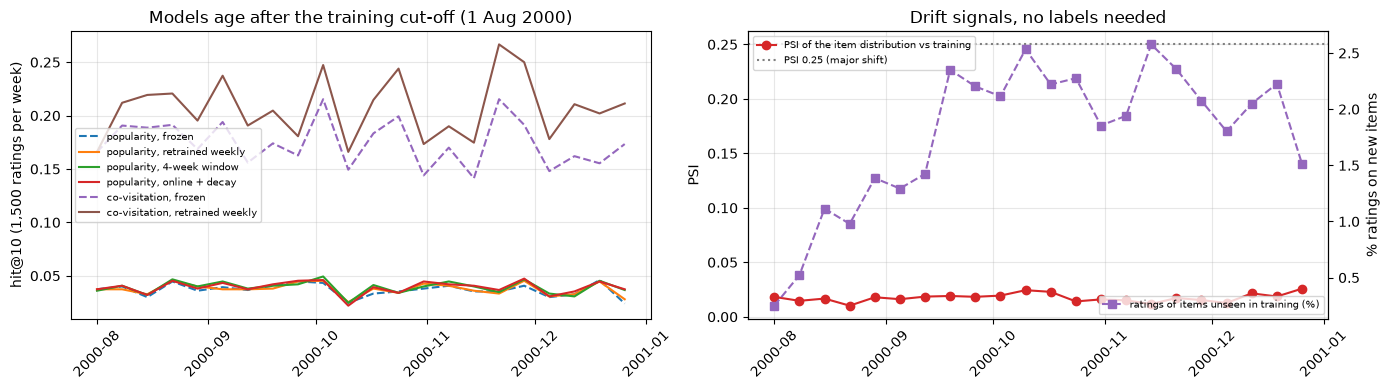

PSI per week: 0.02 0.01 0.02 0.01 0.02 0.02 0.02 0.02 0.02 0.02 0.02 0.02 0.01 0.02 0.02 0.01 0.02 0.02 0.01 0.02 0.02 0.03
share of ratings on items unseen in training, per week: 0.3% 0.5% 1.1% 1.0% 1.4% 1.3% 1.4% 2.4% 2.2% 2.1% 2.5% 2.2% 2.3% 1.9% 1.9% 2.6% 2.4% 2.1% 1.8% 2.1% 2.2% 1.5%


In [4]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for k, v in HITS.items():
    ax[0].plot(DATES, v, "-" if "frozen" not in k else "--", label=k)
ax[0].set_ylabel("hit@10 (1,500 ratings per week)"); ax[0].set_title("Models age after the training cut-off (1 Aug 2000)")
ax[0].legend(fontsize=7); ax[0].grid(alpha=.3); ax[0].tick_params(axis="x", rotation=45)
ax[1].plot(DATES, PSI, "o-", color="tab:red", label="PSI of the item distribution vs training")
ax[1].axhline(0.25, color="gray", ls=":", label="PSI 0.25 (major shift)")
ax2 = ax[1].twinx(); ax2.plot(DATES, [100 * x for x in NEW_ITEMS], "s--", color="tab:purple", label="ratings of items unseen in training (%)")
ax[1].set_ylabel("PSI"); ax2.set_ylabel("% ratings on new items"); ax[1].set_title("Drift signals, no labels needed")
ax[1].legend(loc="upper left", fontsize=7); ax2.legend(loc="lower right", fontsize=7); ax[1].grid(alpha=.3); ax[1].tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()
print("PSI per week:", " ".join(f"{p:.2f}" for p in PSI))
print("share of ratings on items unseen in training, per week:", " ".join(f"{x:.1%}" for x in NEW_ITEMS))

**What the numbers say.**

| model | hit@10, first 4 weeks | last 4 weeks | all 22 weeks |
|---|---|---|---|
| popularity, frozen | 0.038 | 0.033 | 0.037 |
| popularity, retrained weekly / 4-week window / online + decay | 0.038–0.039 | 0.034–0.037 | 0.038–0.039 |
| co-visitation, frozen | 0.184 | **0.160** | 0.175 |
| co-visitation, retrained weekly | 0.204 | **0.201** | **0.207** |

- **The personalized model ages; the popularity model barely does.** Frozen co-visitation loses 2.4 points of hit@10 from the first month to the last (0.184 → 0.160). The weekly-retrained version holds at about 0.20, and over the 22 weeks it is 18 % better (0.207 vs 0.175). Popularity is weak to begin with and changes little whatever we do. The four update strategies end within 0.004 of each other, because which movies are popular overall hardly moved.
- **Even the first week favours the updated model** (0.204 vs 0.184), because weekly retraining includes the most recent transitions. The freshest data is the most predictive.
- **The drift signals disagree with the decay.** PSI on the item distribution stayed at 0.01–0.03 every week, far below the 0.1 that would even count as a moderate shift. Yet the co-visitation model aged. What changed was not *which* movies people rate (the marginal distribution, $P(x)$) but *what follows what* (the transitions the model learns, closer to $P(y \mid x)$). New releases also played a part: ratings of movies never seen in training grew from 0.3 % to about 2–2.6 % of each week, and a frozen model can never recommend them.

**Monitoring only input distributions can miss concept drift.** The reliable signal is the model's own quality on fresh labelled data, which in a recommender arrives for free: what users actually rated next.

## 2. Retrain on a schedule, or when drift is detected?

Retraining costs compute and carries risk: every new model is a deployment. Instead of every week, we can retrain only when the drift signal crosses a threshold. We replay the popularity model with three policies:
- never retrain;
- retrain weekly;
- retrain when the PSI of the past week against the *current* model's training data exceeds 0.25.

For each we count retrains and average hit@10.

In [5]:
def replay(policy):
    model_end = CUT; model = pop_counts(T < CUT); retrains = 0; hits = []
    rng_ = np.random.default_rng(1)
    hist = defaultdict(list)
    for t, u, i in events:
        if t >= CUT: break
        hist[u].append(i)
    for s, e in windows:
        idx = np.where((T >= s) & (T < e))[0]
        eligible = [j for j in idx if len(hist[U_[j]]) >= 5]
        sample = set(rng_.choice(eligible, size=min(1500, len(eligible)), replace=False).tolist())
        h = []
        for j in idx:
            if j in sample:
                h.append(rank_hit(model, hist[U_[j]], I_[j]))
            hist[U_[j]].append(I_[j])
        hits.append(np.mean(h))
        week = pop_counts((T >= s) & (T < e))
        drift = psi(binned(week), binned(pop_counts(T < model_end)))
        if policy == "weekly" or (policy == "on drift" and drift > 0.25):
            model = pop_counts(T < e); model_end = e; retrains += 1
    return np.mean(hits), retrains

for policy in ["never", "weekly", "on drift"]:
    acc, n = replay(policy)
    print(f"retrain {policy:9s}: mean hit@10 {acc:.3f} | retrains {n:2d} of {len(windows)} weeks")

retrain never    : mean hit@10 0.038 | retrains  0 of 22 weeks


retrain weekly   : mean hit@10 0.040 | retrains 22 of 22 weeks


retrain on drift : mean hit@10 0.038 | retrains  0 of 22 weeks


**What the numbers say.**

- Never retraining scored 0.038 mean hit@10.
- Retraining every week scored 0.040, with 22 retrains.
- The drift-triggered policy **never fired**, because the weekly PSI never crossed 0.25 (it never exceeded 0.03), so it behaved exactly like never retraining.

For this popularity model the stakes are small, but the lesson is the one from section 1: a trigger is only as good as the signal behind it. Here the signal was blind to the change that mattered. In practice teams combine:
- **a schedule** as the baseline: nightly or weekly, cheap for simple models;
- **performance-based triggers** on delayed labels: retrain when online hit rate, click-through or task success falls below a threshold;
- **input-drift alarms** that open an investigation rather than retraining automatically.

Every retrain is gated by an offline evaluation and rolled out gradually (canary, A/B), because a new model can be worse than the stale one.

## 3. Drift in an LLM application: what users ask

The same problem in a chatbot: the mix of questions changes (a new product, an outage, a policy change), and the routing, retrieval and evaluation sets built for the old mix go stale. We simulate it with Banking77. A *reference* week of 400 messages is drawn from 60 intents. *Current* weeks of 400 messages then replace a growing share (0 %, 5 %, 10 %, 20 %, 40 %) with messages from 17 intents never seen before. For each shift level, 20 trials, three detectors on bge-small embeddings, each alarming at 5 % significance:

- **centroid shift**: the cosine distance between the mean embeddings, compared with a threshold from the no-drift trials;
- **MMD** with an RBF kernel and a permutation test;
- **classifier two-sample test**: cross-validated AUC of a logistic regression telling reference from current, compared with a permutation threshold.

At 0 % shift, the alarm rate is the false-alarm rate. Above it, the alarm rate is the detection power.

100 trials in 33s
  0% new intents: alarm rate  centroid   5% | MMD   5% | classifier   5% | mean classifier AUC 0.498
  5% new intents: alarm rate  centroid  15% | MMD   5% | classifier  20% | mean classifier AUC 0.499
 10% new intents: alarm rate  centroid  15% | MMD   5% | classifier  15% | mean classifier AUC 0.483
 20% new intents: alarm rate  centroid  30% | MMD  25% | classifier  25% | mean classifier AUC 0.490
 40% new intents: alarm rate  centroid  90% | MMD 100% | classifier 100% | mean classifier AUC 0.554


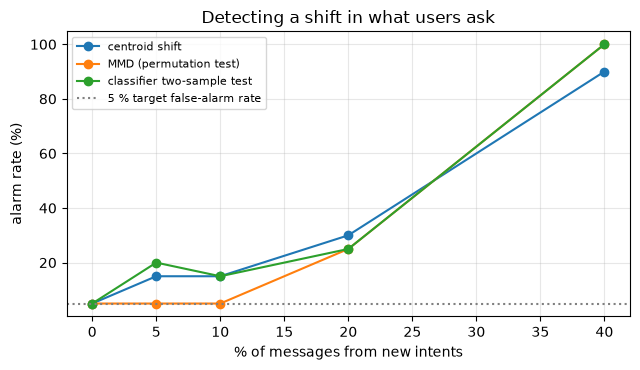

In [6]:
from datasets import load_dataset
from sentence_transformers import SentenceTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import roc_auc_score
import datasets; datasets.disable_progress_bars()
bank = load_dataset("PolyAI/banking77", split="train")
emb = SentenceTransformer("BAAI/bge-small-en-v1.5", device="cuda" if __import__("torch").cuda.is_available() else "cpu")
E = emb.encode(bank["text"], batch_size=128, normalize_embeddings=True); yb = np.array(bank["label"])
r = np.random.default_rng(0); perm = r.permutation(77)
OLD, NEW = perm[:60], perm[60:]
old_idx, new_idx = np.where(np.isin(yb, OLD))[0], np.where(np.isin(yb, NEW))[0]

def mmd2_from_kernel(K, a, b):
    """Squared MMD between the samples indexed by a and b, from a precomputed kernel matrix K."""
    return K[np.ix_(a, a)].mean() + K[np.ix_(b, b)].mean() - 2 * K[np.ix_(a, b)].mean()

def detectors(ref, cur, rng_, n_perm=200):
    out = {}
    out["centroid"] = 1 - float(ref.mean(0) @ cur.mean(0) / np.linalg.norm(ref.mean(0)) / np.linalg.norm(cur.mean(0)))
    Z = np.vstack([ref, cur]); n = len(ref)
    D2 = np.clip(2 - 2 * Z @ Z.T, 0, None)                        # squared distances of unit vectors, from dot products
    K = np.exp(-D2 / np.median(D2[D2 > 0]))                       # RBF kernel, bandwidth by the median heuristic
    a, b = np.arange(n), np.arange(n, len(Z))
    stat = mmd2_from_kernel(K, a, b); null = []
    for _ in range(n_perm):                                       # permutation test: shuffle which sample each point came from
        p = rng_.permutation(len(Z)); null.append(mmd2_from_kernel(K, p[:n], p[n:]))
    out["mmd_p"] = (1 + np.sum(np.array(null) >= stat)) / (1 + n_perm)
    lab = np.r_[np.zeros(n), np.ones(len(cur))]
    proba = cross_val_predict(LogisticRegression(max_iter=500, C=1.0), Z, lab, cv=5, method="predict_proba")[:, 1]
    out["auc"] = roc_auc_score(lab, proba)
    return out

N, TRIALS = 400, 20
LEVELS = [0.0, 0.05, 0.10, 0.20, 0.40]
DRIFT = {lvl: [] for lvl in LEVELS}
t0 = time.time()
for lvl in LEVELS:
    for k in range(TRIALS):
        rr = np.random.default_rng(100 * k + int(lvl * 100))
        ref = E[rr.choice(old_idx, N, replace=False)]
        n_new = int(lvl * N)
        cur = E[np.r_[rr.choice(old_idx, N - n_new, replace=False), rr.choice(new_idx, n_new, replace=False)].astype(int)]
        DRIFT[lvl].append(detectors(ref, cur, rr))
print(f"{len(LEVELS) * TRIALS} trials in {time.time() - t0:.0f}s")
cent_thr = np.quantile([d["centroid"] for d in DRIFT[0.0]], 0.95)        # calibrated on no-drift trials
auc_thr = np.quantile([d["auc"] for d in DRIFT[0.0]], 0.95)
POWER = {}
for lvl in LEVELS:
    ds = DRIFT[lvl]
    POWER[lvl] = (np.mean([d["centroid"] > cent_thr for d in ds]), np.mean([d["mmd_p"] < 0.05 for d in ds]), np.mean([d["auc"] > auc_thr for d in ds]))
    print(f"{int(lvl * 100):3d}% new intents: alarm rate  centroid {POWER[lvl][0]:4.0%} | MMD {POWER[lvl][1]:4.0%} | classifier {POWER[lvl][2]:4.0%} "
          f"| mean classifier AUC {np.mean([d['auc'] for d in ds]):.3f}")

fig, ax = plt.subplots(figsize=(6.5, 3.8))
for j, name in enumerate(["centroid shift", "MMD (permutation test)", "classifier two-sample test"]):
    ax.plot([100 * l for l in LEVELS], [100 * POWER[l][j] for l in LEVELS], "o-", label=name)
ax.axhline(5, color="gray", ls=":", label="5 % target false-alarm rate")
ax.set_xlabel("% of messages from new intents"); ax.set_ylabel("alarm rate (%)"); ax.set_title("Detecting a shift in what users ask")
ax.grid(alpha=.3); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

**What the numbers say.**

| % of messages from new intents | 0 % | 5 % | 10 % | 20 % | 40 % |
|---|---|---|---|---|---|
| centroid shift | 5 % | 15 % | 15 % | 30 % | 90 % |
| MMD (permutation test) | 5 % | 5 % | 5 % | 25 % | **100 %** |
| classifier two-sample test | 5 % | 20 % | 15 % | 25 % | **100 %** |

- **False alarms are controlled**: all three alarm on 5 % of the no-drift trials, as calibrated.
- **Whole-window tests only see big shifts.** With 400 messages per window, a shift where 1 message in 5 comes from intents never seen before is detected only 25–30 % of the time. At 40 % all three detect it almost always. The classifier's AUC stays at 0.48–0.50 up to 20 %, so the two windows are statistically indistinguishable as a whole.
- **That is why per-message monitoring matters.** Notebook 25 flagged *individual* messages far from every known intent and clustered them, and it surfaced all 7 unknown intents. A distribution test asks "is this week different?"; a novelty flag asks "which messages are new?", and it is far more sensitive to a new topic that is still small. Use both: distribution tests (with larger windows, or embeddings fine-tuned on your domain) as a coarse alarm, and novelty flags plus clustering to see *what* changed.

## Results

| question | measured | lesson |
|---|---|---|
| how fast does a frozen model age? | co-visitation recommender: hit@10 0.184 → 0.160 over 22 weeks; weekly retraining holds ~0.20 (+18 % overall) | personalized models decay; retrain them |
| do update strategies matter for popularity? | frozen, weekly, 4-week window, online + decay all within 0.004 | simple aggregates are robust; update what learns relations |
| do input-distribution monitors catch it? | PSI 0.01–0.03 every week while the model aged; new items 0.3 % → ~2 % of ratings | input drift ≠ concept drift; monitor quality |
| drift-triggered retraining | never fired (PSI < 0.25), same result as never retraining | a trigger is only as good as its signal |
| detecting a change in what users ask (embeddings) | 5 % false alarms; 25–30 % detection at a 20 % shift, 90–100 % at 40 % | window tests catch big shifts; per-message novelty catches new topics |

## In production

**Keep models fresh.**
- Retrain on a schedule matched to how fast your data moves: daily for news and e-commerce recommenders, weekly or monthly for slower domains.
- Use warm starts and sliding windows for large models, and online updates (decayed counts, streaming features, bandits) where minutes matter.
- Gate every new model with an offline evaluation on the most recent data, roll it out behind a canary or A/B test, and keep the previous model ready for rollback.

**Monitor at three levels.**
1. **Inputs.** PSI or KS on key features, embedding drift tests (MMD, classifier two-sample) on text and images, the share of unseen items, users and intents.
2. **Outputs.** Prediction distribution, confidence, refusal and fallback rates (notebooks 22–23).
3. **Outcomes.** Online quality from delayed labels: clicks, purchases, ratings, task success, user feedback. This is the only level that measures the thing you care about.

Tools: Evidently, NannyML, WhyLabs and Arize for tabular and embedding drift, and the observability stack of notebook 15 for LLM traces.

**For LLM applications.**
- The model weights do not drift, but everything around them does: user questions, documents in the RAG index, tool APIs, and the provider's model version behind an API name.
- Re-run the evaluation set on every change.
- Track new-intent clusters weekly (notebook 25).
- Refresh the retrieval index and the evaluation set from production traffic.

**Failure modes.**
- Monitoring only inputs and missing concept drift.
- Alarms nobody owns.
- Retraining automatically on corrupted or poisoned data.
- Feedback loops where the model trains on the consequences of its own recommendations.
- Comparing windows too small to detect anything.
- Silent upstream changes: a renamed field, a new tokenizer, a new API model version.

**Next:** notebook 13 (LLM application patterns), or notebook 15 to wire these monitors into observability.